# Milling condition safety monitor — reproducible analysis

**ME-446 Artificial Intelligence & Internet of Things — Complex Engineering Problem, Fall 2026**
Department of Mechanical Engineering, NED University of Engineering and Technology, Karachi.

**Problem.** Detect non-optimal / dangerous milling conditions (radial depth of cut RDOC = 8 mm)
from accelerometer and spindle/drive-current statistics, so that an aggressive cut can be flagged
before it damages the tool, spindle or workpiece. The task is binary **classification**; the
positive (dangerous) class is the minority at 21.9 %.

**Dataset.** Piecuch, M. & Żabiński, T., *A new open dataset from a milling process – data for
classification and estimation of tool life*, Scientific Data 12, 650 (2025).
DOI [10.1038/s41597-025-04923-y](https://doi.org/10.1038/s41597-025-04923-y); data
DOI [10.6084/m9.figshare.28589216](https://doi.org/10.6084/m9.figshare.28589216), CC BY 4.0.
The authors' processed 120-statistic feature matrix is used; the 25 GB raw time-series archive
is not redistributed here.

This notebook reproduces, in order: data loading and auditing, cleaning and target definition,
exploratory analysis, leakage-safe validation design, comparison of four models, threshold
selection, evaluation of the selected model, feature importance, and the unseen-case
demonstration. It reads the raw files under `data/raw/` and does **not** overwrite the saved
artifacts in `models/` and `figures/`.

**Runtime:** about 3–6 minutes on a laptop CPU.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve
from sklearn.model_selection import LeaveOneGroupOut

warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import DATA_PROCESSED, FIGURES, MODELS, RAW_CSV, RAW_XLSX, RANDOM_STATE, SENSOR_COLUMNS
from src.data import build_clean_dataset, load_raw_csv, load_raw_metadata
from src.modeling import (
    MODEL_LABELS,
    base_pipeline,
    choose_threshold,
    metric_dict,
    run_cv,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 11})
PALETTE = {"Optimal (RDOC 4.5 mm)": "#2E86AB", "Non-optimal (RDOC 8 mm)": "#D1495B"}
CLASS_ORDER = ["Optimal (RDOC 4.5 mm)", "Non-optimal (RDOC 8 mm)"]
pd.set_option("display.width", 140)

print(f"Project root : {ROOT}")
print(f"Random seed  : {RANDOM_STATE}")
print(f"Raw CSV      : {RAW_CSV.exists()}  ({RAW_CSV.name})")
print(f"Raw workbook : {RAW_XLSX.exists()}  ({RAW_XLSX.name})")
print(f"Sensor cols  : {len(SENSOR_COLUMNS)}")

# src.modeling sets the Agg backend at import time; restore the inline backend.
%matplotlib inline


Project root : /home/shahbaz/Desktop/New Folder/milling-cep
Random seed  : 20261025
Raw CSV      : True  (FeatureAndMetadata_Milling.csv)
Raw workbook : True  (metadata.xlsx)
Sensor cols  : 120


## 1. Raw data and audit

The authors' CSV is a semicolon-delimited export with a UTF-8 BOM, a redundant first header row
(`Column1 … Column131`), the real variable names on row 2, comma decimals in the metadata columns
and dot decimals in the 120 sensor columns. `src.data.load_raw_csv` handles these quirks explicitly
rather than relying on defaults.

Two independent sources are available: the feature CSV and `metadata.xlsx`. They are cross-checked
row for row before any modelling, so a silent misalignment cannot propagate into the results.

In [2]:
raw = load_raw_csv()
meta = load_raw_metadata()

print(f"Feature CSV : {raw.shape[0]} cycles x {raw.shape[1]} columns")
print(f"Metadata    : {meta.shape[0]} rows x {meta.shape[1]} columns")
display(raw[["FileName", "TollIndex", "ADOC", "RDOC", "CycleToFailure",
             "Accelerometer - Spindle +Y - mean", "Current - Spindle L1 - std"]].head())

audit_basics = pd.Series({
    "missing values": int(raw.isna().sum().sum()),
    "duplicate rows": int(raw.duplicated().sum()),
    "duplicate sensor vectors": int(raw.duplicated(subset=SENSOR_COLUMNS).sum()),
    "infinite sensor values": int(np.isinf(raw[SENSOR_COLUMNS].astype(float)).sum().sum()),
    "experiments": int(raw["FileName"].str.extract(r"^(P\d+)_")[0].nunique()),
    "layers": int(raw["FileName"].str.extract(r"^(P\d+_F\d+)_")[0].nunique()),
    "tools": int(raw["TollIndex"].nunique()),
}, name="value")
display(audit_basics.to_frame())

Feature CSV : 968 cycles x 131 columns
Metadata    : 968 rows x 13 columns


,FileName,TollIndex,ADOC,RDOC,CycleToFailure,Accelerometer - Spindle +Y - mean,Current - Spindle L1 - std
0,P002_F01_C1,2,5,8,49,0.944602,37925.819704
1,P002_F01_C2,2,5,8,48,-0.904161,53870.874870
2,P002_F01_C3,2,5,8,47,19.618137,53995.568940
3,P002_F01_C4,2,5,8,46,0.580999,52658.901263
4,P002_F02_C1,2,5,8,45,4.965820,41617.387680


,value
missing values,0
duplicate rows,0
duplicate sensor vectors,0
infinite sensor values,0
experiments,24
layers,172
tools,14


## 2. Cleaning and target definition

**Target.** `RDOC_class = 1` when RDOC = 8 mm (non-optimal / dangerous) and `0` when RDOC = 4.5 mm
(optimal). The original paper modelled tool wear; this CEP deliberately does **not** reproduce that
target, so the analysis is a new problem on the same public data.

**Preserved rows.** All 968 cycles are kept, including the single-cycle early failure and the 14
records with `CycleToFailure = 0` (right-censored). Deleting difficult records would bias the
class balance and break the source paper's intended use of the data. Outliers are flagged, never
removed.

**Excluded from the model.** Identifiers, process settings, material hardness, tool metadata and
remaining-life counters are excluded from the feature matrix. `ToolRotation`, `FeedRate` and
`ToolDiameter` are constant in this campaign and cannot carry information.

In [3]:
from src.data import assign_folds

clean, meta_aligned, audit = build_clean_dataset()
folds = assign_folds(clean)
clean = clean.merge(
    folds.drop(columns=["ExperimentID", "ToolIndex", "RDOC_class", "class_label"]),
    on="FileName", how="left", validate="one_to_one",
)

print(f"Cleaned cycles      : {len(clean)}")
print(f"Canonical columns   : {clean.shape[1]}")
print(f"Zero-variance sensor: {int((clean[SENSOR_COLUMNS].std() == 0).sum())}")
print(f"Missing values      : {int(clean[SENSOR_COLUMNS].isna().sum().sum())}")
print(f"Outlier-flagged     : {int(clean['outlier_flag'].sum())} (retained)")

balance = pd.DataFrame({
    "cycles": clean["class_label"].value_counts().reindex(CLASS_ORDER),
    "share": clean["class_label"].value_counts(normalize=True).reindex(CLASS_ORDER),
})
display(balance)

tool_map = (
    clean.groupby("ToolIndex")
    .agg(cycles=("FileName", "size"), RDOC_mm=("RDOC_mm", "first"),
         ADOC_mm=("ADOC_mm", "first"), tool_type=("MillingToolType", "first"),
         hardness=("Hardness_HRC", "mean"), class_label=("class_label", "first"))
    .reset_index()
)
display(tool_map)

print("Experiments containing both classes:", int((clean.groupby('ExperimentID')['RDOC_class'].nunique() > 1).sum()))
print("Tools containing both classes      :", int((clean.groupby('ToolIndex')['RDOC_class'].nunique() > 1).sum()))
print("Tool-type 2 cycles at RDOC = 8 mm  :", int(((clean['MillingToolType'] == 2) & (clean['RDOC_class'] == 1)).sum()))

Cleaned cycles      : 968
Canonical columns   : 149
Zero-variance sensor: 0
Missing values      : 0
Outlier-flagged     : 52 (retained)


,cycles,share
class_label,,
Optimal (RDOC 4.5 mm),756,0.780992
Non-optimal (RDOC 8 mm),212,0.219008


,ToolIndex,cycles,RDOC_mm,ADOC_mm,tool_type,hardness,class_label
0,2,48,8.0,5,1,36.614167,Non-optimal (RDOC 8 mm)
1,3,44,8.0,10,1,39.566591,Non-optimal (RDOC 8 mm)
2,4,41,8.0,5,1,35.330000,Non-optimal (RDOC 8 mm)
3,5,51,8.0,10,1,38.005686,Non-optimal (RDOC 8 mm)
4,6,28,8.0,5,1,40.000000,Non-optimal (RDOC 8 mm)
5,7,124,4.5,10,1,40.330000,Optimal (RDOC 4.5 mm)
6,8,116,4.5,5,1,40.933448,Optimal (RDOC 4.5 mm)
7,9,149,4.5,5,1,38.202483,Optimal (RDOC 4.5 mm)
8,10,15,4.5,10,1,37.330000,Optimal (RDOC 4.5 mm)
9,11,1,4.5,10,1,37.170000,Optimal (RDOC 4.5 mm)


Experiments containing both classes: 0
Tools containing both classes      : 0
Tool-type 2 cycles at RDOC = 8 mm  : 0


### Why the split strategy matters

RDOC and ADOC are **constant within every experiment and every tool** (0 experiments and 0 tools
contain both classes). A random row split therefore puts cycles from the same tool in both training
and test, and the model can memorise that tool's vibration/current signature instead of learning the
physics of the cut. This is target leakage through grouping, not through a column.

The honest estimate must hold out whole tool groups. The notebook uses 5-fold grouped validation on
`tool_5fold` as the primary estimate and leave-one-tool-out as a stress test. A random 5-fold
score is reported by the pipeline only as a leakage control.

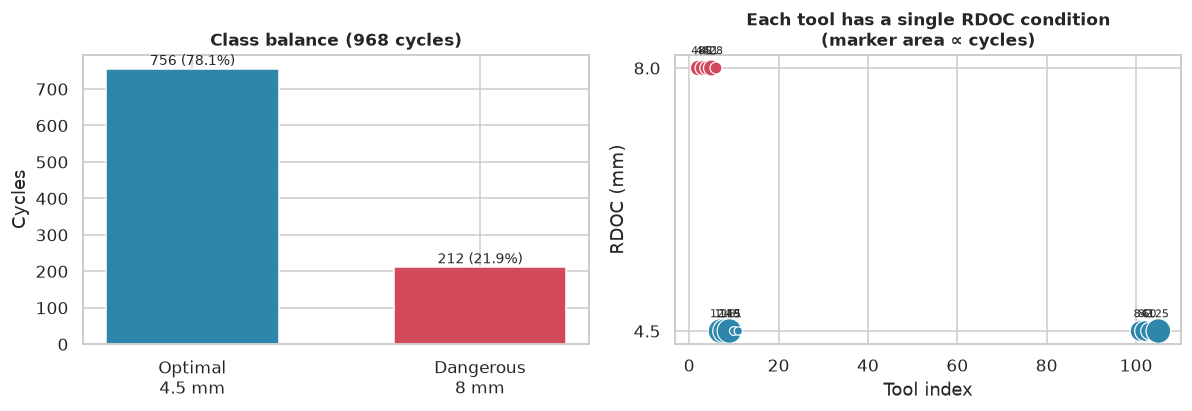

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))

counts = clean["class_label"].value_counts().reindex(CLASS_ORDER)
axes[0].bar(range(2), counts.values, color=[PALETTE[c] for c in CLASS_ORDER], width=0.6)
axes[0].set_xticks(range(2), ["Optimal\n4.5 mm", "Dangerous\n8 mm"])
axes[0].set_ylabel("Cycles")
axes[0].set_title("Class balance (968 cycles)")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 10, f"{v} ({v/len(clean):.1%})", ha="center", fontsize=9)

order = tool_map.sort_values(["RDOC_mm", "ToolIndex"])
ypos = np.arange(len(order))
axes[1].scatter(order["ToolIndex"], order["RDOC_mm"],
                c=[PALETTE[CLASS_ORDER[1]] if r == 8 else PALETTE[CLASS_ORDER[0]] for r in order["RDOC_mm"]],
                s=np.clip(order["cycles"] * 2.2, 30, 260), edgecolor="white", linewidth=0.8)
axes[1].set_xlabel("Tool index")
axes[1].set_ylabel("RDOC (mm)")
axes[1].set_yticks([4.5, 8.0])
axes[1].set_title("Each tool has a single RDOC condition\n(marker area ∝ cycles)")
for _, row in order.iterrows():
    axes[1].annotate(int(row["cycles"]), (row["ToolIndex"], row["RDOC_mm"]),
                     textcoords="offset points", xytext=(0, 9), ha="center", fontsize=7)

fig.tight_layout()
plt.show()

## 3. Exploratory analysis and engineering plausibility

The class separation should be explainable by cutting mechanics: a larger radial engagement raises
the chip load, the cutting force and therefore the spindle/drive current and vibration amplitude.
The strongest univariate features are checked before any model is fitted, because a classifier that
works for the wrong reason is not useful evidence.

,feature,auc,direction
46,Accelerometer - Y Driving axle +Y - mean,0.939,higher in dangerous
43,Accelerometer - X Driving axle +Z - mean,0.935,higher in dangerous
71,Current - Driving axle X L1 - std,0.913,higher in dangerous
73,Current - Driving axle X L3 - std,0.913,higher in dangerous
72,Current - Driving axle X L2 - std,0.913,higher in dangerous
68,Current - Spindle L1 - std,0.894,higher in dangerous
69,Current - Spindle L2 - std,0.894,higher in dangerous
70,Current - Spindle L3 - std,0.894,higher in dangerous
40,Accelerometer - Spindle +Y - mean,0.889,higher in dangerous
12,Current - Driving axle X L2 - min,0.116,lower in dangerous


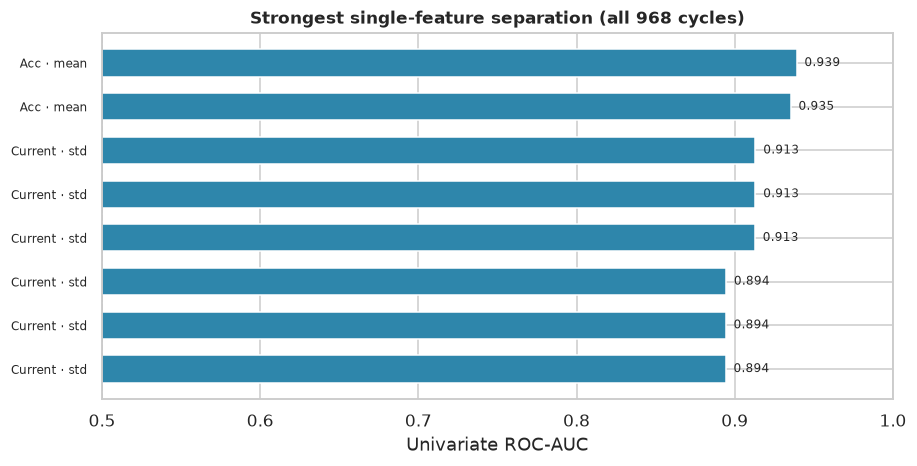

In [5]:
from sklearn.metrics import roc_auc_score

y = clean["RDOC_class"].astype(int).to_numpy()
rows = []
for col in SENSOR_COLUMNS:
    auc = roc_auc_score(y, clean[col].astype(float))
    rows.append({"feature": col, "auc": auc, "direction": "higher in dangerous" if auc >= 0.5 else "lower in dangerous"})
uni = pd.DataFrame(rows).assign(strength=lambda d: (d["auc"] - 0.5).abs()).sort_values("strength", ascending=False)
display(uni.head(10)[["feature", "auc", "direction"]].round(3))

top8 = uni.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.barh(range(len(top8)), top8["auc"], color="#2E86AB", height=0.62)
ax.axvline(0.5, color="#777777", linestyle="--", linewidth=1)
ax.set_yticks(range(len(top8)), [f.split(" - ")[0].replace("Accelerometer", "Acc") + " · " + f.split(" - ")[-1]
                                  for f in top8["feature"]], fontsize=8)
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("Univariate ROC-AUC")
ax.set_title("Strongest single-feature separation (all 968 cycles)")
for i, (v, f) in enumerate(zip(top8["auc"], top8["feature"])):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=8)
fig.tight_layout()
plt.show()

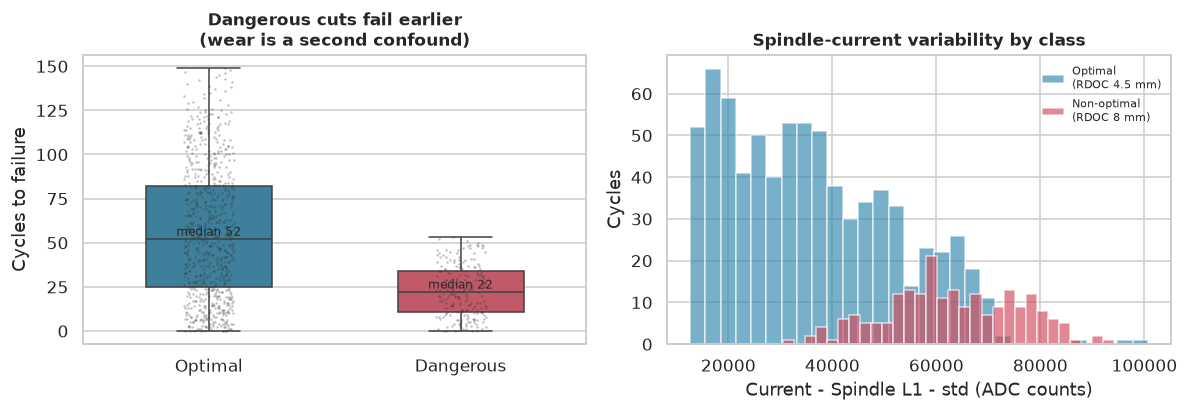

,count,mean,median,min,max
class_label,,,,,
Optimal (RDOC 4.5 mm),756,55.8,52.0,0,149
Non-optimal (RDOC 8 mm),212,22.7,22.0,0,53


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))

sns.boxplot(data=clean, x="class_label", y="CycleToFailure", order=CLASS_ORDER,
            palette=PALETTE, width=0.5, showfliers=False, ax=axes[0])
sns.stripplot(data=clean, x="class_label", y="CycleToFailure", order=CLASS_ORDER,
              color="#333333", size=1.6, alpha=0.3, ax=axes[0])
axes[0].set_xticks(range(2), ["Optimal", "Dangerous"])
axes[0].set_xlabel("")
axes[0].set_ylabel("Cycles to failure")
axes[0].set_title("Dangerous cuts fail earlier\n(wear is a second confound)")
for i, c in enumerate(CLASS_ORDER):
    axes[0].text(i, clean.loc[clean["class_label"] == c, "CycleToFailure"].median() + 2,
                 f"median {clean.loc[clean['class_label'] == c, 'CycleToFailure'].median():.0f}",
                 ha="center", fontsize=8)

feature = "Current - Spindle L1 - std"
for c in CLASS_ORDER:
    subset = clean.loc[clean["class_label"] == c, feature]
    axes[1].hist(subset, bins=30, alpha=0.65, label=c.replace(" (RDOC", "\n(RDOC"), color=PALETTE[c])
axes[1].set_xlabel("Current - Spindle L1 - std (ADC counts)")
axes[1].set_ylabel("Cycles")
axes[1].set_title("Spindle-current variability by class")
axes[1].legend(fontsize=7, frameon=False)

fig.tight_layout()
plt.show()

display(clean.groupby("class_label")["CycleToFailure"].agg(["count", "mean", "median", "min", "max"]).reindex(CLASS_ORDER).round(1))

### Engineering insights from the EDA

1. **The dangerous condition is a minority.** 212 of 968 cycles (21.9 %) and 5 of 14 tools run at
   RDOC = 8 mm. Accuracy is a poor headline metric here; recall on the dangerous class, PR-AUC and
   the confusion matrix carry the engineering meaning.
2. **The design is confounded with tool identity.** Because each tool has one RDOC, any random split
   lets a model recognise the tool. Grouped validation is mandatory for an honest number.
3. **The sensor signal is physically credible.** Drive-axis mean acceleration and drive/spindle
   current standard deviation separate the classes with univariate AUCs of 0.89–0.94, in the
   direction expected from a larger radial engagement (higher force, current and vibration).
4. **Wear is a competing explanation.** Dangerous tools fail sooner (mean 22.7 vs 55.8 cycles), so
   part of the separation may reflect wear stage rather than RDOC alone. This is treated as a
   limitation and probed with a remaining-life view in the dashboard.
5. **Material and tool type differ by class.** The dangerous group has lower hardness and is entirely
   tool type 1; type 2 never appears at RDOC = 8 mm. These are plausible false-positive drivers.

## 4. Leakage-safe validation design

The feature matrix is the 120 sensor statistics only. Groups are tool identities. The primary scheme
uses five grouped folds; the stress test holds out one tool at a time. Hyperparameters are tuned
**inside** each outer fold on the training groups, so the outer estimate never sees the held-out
tool during tuning.

In [7]:
X = clean[SENSOR_COLUMNS].copy()
tool_groups = clean["ToolIndex"].astype(int).to_numpy()
tool5_groups = clean["tool_5fold"].astype(int).to_numpy()

print(f"X: {X.shape[0]} cycles x {X.shape[1]} sensor features")
print(f"y: {y.sum()} dangerous / {len(y) - y.sum()} optimal")
print(f"Tools: {len(np.unique(tool_groups))};  grouped folds: {len(np.unique(tool5_groups))}")

fold_view = (
    clean.groupby("tool_5fold")
    .agg(tools=("ToolIndex", lambda s: ", ".join(str(v) for v in sorted(s.unique()))),
         cycles=("FileName", "size"), dangerous=("RDOC_class", "sum"))
    .assign(dangerous_share=lambda d: (d["dangerous"] / d["cycles"]).round(3))
)
display(fold_view)

X: 968 cycles x 120 sensor features
y: 212 dangerous / 756 optimal
Tools: 14;  grouped folds: 5


,tools,cycles,dangerous,dangerous_share
tool_5fold,,,,
0,"2, 7, 101",256,48,0.188
1,"3, 8, 102",242,44,0.182
2,"4, 9, 103",250,41,0.164
3,"5, 10, 105",191,51,0.267
4,"6, 11",29,28,0.966


## 5. Model comparison

Four approaches are compared, chosen to span the bias–variance and interpretability range:

| Model | Role | Why it is appropriate |
|---|---|---|
| Dummy (prior) | Baseline | Shows what a no-skill classifier achieves on this class balance. |
| Logistic regression | Interpretable linear model | 120 correlated, heavy-tailed sensor statistics; robust scaling and a linear decision boundary give a transparent reference. |
| Random forest | Non-linear ensemble | Captures thresholds and interactions between vibration and current channels without hand-crafted features; handles 120 correlated inputs. |
| Histogram gradient boosting | Modern boosted ensemble | Strong tabular learner; included to test whether boosting beats bagging on this dataset. |

All models use the same `signed-log1p` transform, which compresses the very large ADC counts while
preserving sign. Class imbalance is handled by balanced class weights (where the library supports
them) and by threshold selection, not by resampling; synthetic samples would distort the physical
sensor distribution.

Metrics: ROC-AUC and PR-AUC (threshold-independent), then recall, precision, F1, specificity, MCC,
balanced accuracy and Brier score at a fixed 0.5 threshold for comparison. The operating threshold
is chosen afterwards on the out-of-fold probabilities.

In [8]:
model_names = ["Dummy", "LogisticRegression", "RandomForest", "HistGradientBoosting"]
results = {}

for name in model_names:
    print(f"Running {MODEL_LABELS[name]} ...")
    results[name] = run_cv(
        name, X, y, tool5_groups, LeaveOneGroupOut(),
        scheme="tool_5fold", tune=name != "Dummy", verbose=False,
    )

comparison = pd.DataFrame([
    {"model": MODEL_LABELS[name], **{k: r.pooled_metrics[k] for k in
        ["roc_auc", "pr_auc", "balanced_accuracy", "recall", "precision", "f1", "specificity", "mcc", "brier", "accuracy"]}}
    for name, r in results.items()
]).sort_values("pr_auc", ascending=False)

display(comparison.round(3).reset_index(drop=True))

Running Dummy (prior) ...


Running Logistic regression ...


Running Random forest ...


Running Hist gradient boosting ...


,model,roc_auc,pr_auc,balanced_accuracy,recall,precision,f1,specificity,mcc,brier,accuracy
0,Hist gradient boosting,0.936,0.782,0.863,0.877,0.620,0.727,0.849,0.650,0.107,0.855
1,Logistic regression,0.940,0.733,0.907,0.948,0.663,0.781,0.865,0.725,0.093,0.883
2,Random forest,0.942,0.688,0.898,0.892,0.724,0.799,0.905,0.742,0.082,0.902
3,Dummy (prior),0.386,0.184,0.500,0.000,0.000,0.000,1.000,0.000,0.173,0.781


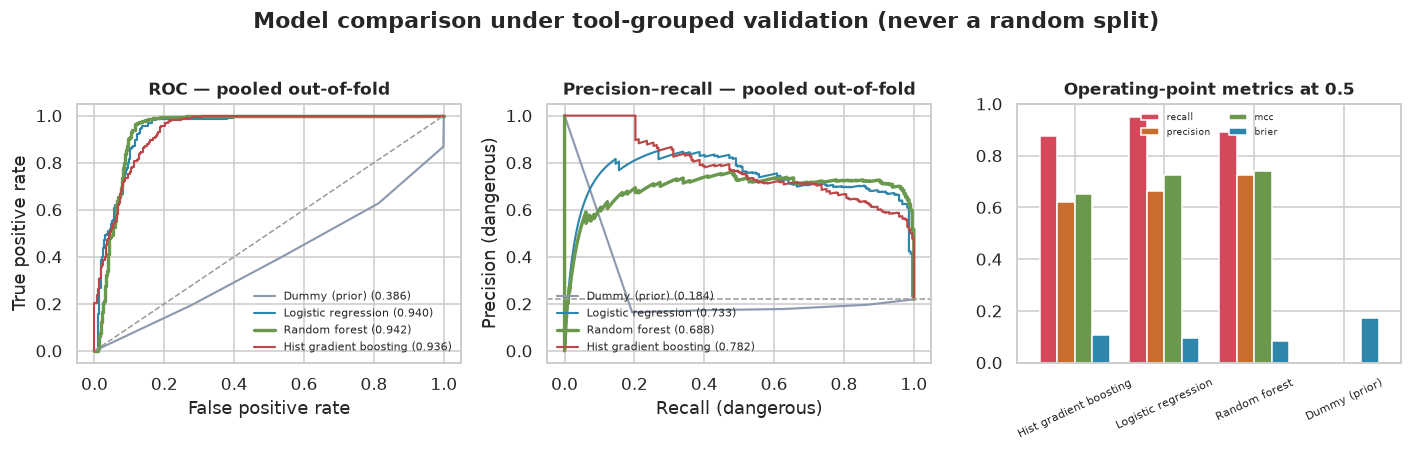

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.0))
colors = {"Dummy": "#8D99AE", "LogisticRegression": "#2E86AB", "RandomForest": "#6A994E", "HistGradientBoosting": "#BC4749"}

for name, res in results.items():
    fpr, tpr, _ = roc_curve(y, res.oof_prob)
    axes[0].plot(fpr, tpr, color=colors[name], linewidth=2.2 if name == "RandomForest" else 1.4,
                 label=f"{MODEL_LABELS[name]} ({res.pooled_metrics['roc_auc']:.3f})")
    precision, recall, _ = precision_recall_curve(y, res.oof_prob)
    axes[1].plot(recall, precision, color=colors[name], linewidth=2.2 if name == "RandomForest" else 1.4,
                 label=f"{MODEL_LABELS[name]} ({res.pooled_metrics['pr_auc']:.3f})")

axes[0].plot([0, 1], [0, 1], "--", color="#999999", linewidth=1)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC — pooled out-of-fold"); axes[0].legend(frameon=False, fontsize=7, loc="lower right")

axes[1].axhline(y.mean(), color="#999999", linestyle="--", linewidth=1)
axes[1].set_xlabel("Recall (dangerous)"); axes[1].set_ylabel("Precision (dangerous)")
axes[1].set_title("Precision–recall — pooled out-of-fold"); axes[1].legend(frameon=False, fontsize=7, loc="lower left")

plot = comparison.set_index("model")[["recall", "precision", "mcc", "brier"]]
plot.plot(kind="bar", ax=axes[2], width=0.78,
          color=["#D1495B", "#C76D2E", "#6A994E", "#2E86AB"], legend=False)
axes[2].set_title("Operating-point metrics at 0.5")
axes[2].set_xlabel("")
axes[2].tick_params(axis="x", rotation=25, labelsize=7)
axes[2].set_ylim(0, 1.0)
axes[2].legend(fontsize=6, frameon=False, ncol=2, loc="upper center")

fig.suptitle("Model comparison under tool-grouped validation (never a random split)", fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()

## 6. Threshold selection and selected model

Random forest is selected on the **operating-point** trade-off rather than on a single ranking metric:
it gives the best combination of recall, precision, MCC, balanced accuracy and Brier score after
threshold tuning, and its errors are easier to explain to a process engineer than a boosted ensemble
that changes more between folds. Histogram gradient boosting has the higher threshold-independent
PR-AUC; this is reported honestly rather than hidden.

For a safety monitor, missing a dangerous cut (false negative) is worse than a false alarm. The
threshold maximising F1 on the pooled out-of-fold probabilities is used as the pre-registered
operating point; the Streamlit dashboard exposes it as a slider so the consequence of moving it can
be seen directly.

In [10]:
best_name = "RandomForest"
best = results[best_name]
threshold_info = choose_threshold(y, best.oof_prob)
threshold = threshold_info["max_f1_threshold"]
selected = metric_dict(y, best.oof_prob, threshold=threshold)

print(f"Threshold (max F1 on grouped OOF): {threshold:.4f}")
print(f"High-recall alternative          : {threshold_info['high_recall_threshold']:.4f} "
      f"(recall {threshold_info['high_recall_recall']:.3f}, precision {threshold_info['high_recall_precision']:.3f})")
print()
print(f"Recall (dangerous): {selected['recall']:.3f}")
print(f"Precision         : {selected['precision']:.3f}")
print(f"F1                : {selected['f1']:.3f}")
print(f"MCC               : {selected['mcc']:.3f}")
print(f"Balanced accuracy : {selected['balanced_accuracy']:.3f}")
print(f"Brier score       : {selected['brier']:.3f}")
print(f"ROC-AUC / PR-AUC  : {selected['roc_auc']:.3f} / {selected['pr_auc']:.3f}")
print(f"Confusion matrix  : {selected['confusion_matrix']}")

Threshold (max F1 on grouped OOF): 0.4437
High-recall alternative          : 0.4991 (recall 0.901, precision 0.726)

Recall (dangerous): 0.962
Precision         : 0.699
F1                : 0.810
MCC               : 0.762
Balanced accuracy : 0.923
Brier score       : 0.082
ROC-AUC / PR-AUC  : 0.942 / 0.688
Confusion matrix  : [[668, 88], [8, 204]]


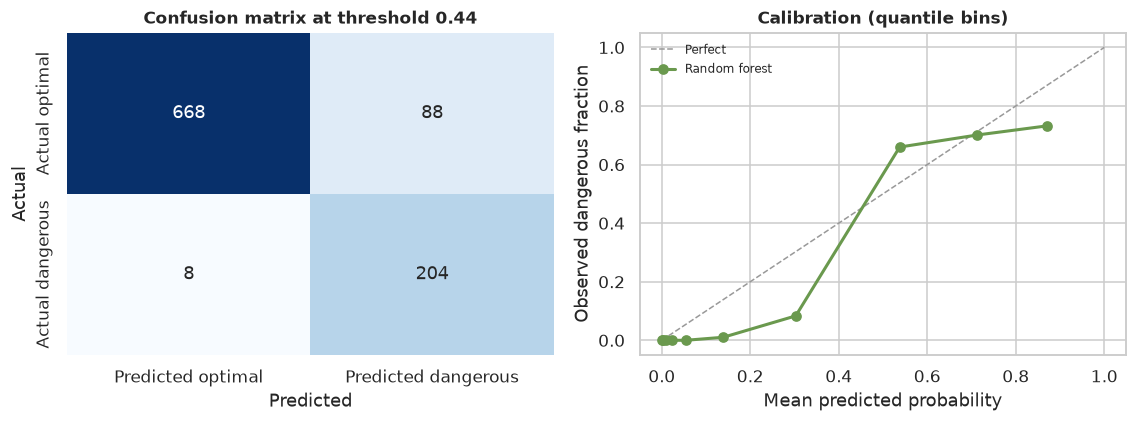

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))

cm = np.array(selected["confusion_matrix"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Predicted optimal", "Predicted dangerous"],
            yticklabels=["Actual optimal", "Actual dangerous"])
axes[0].set_title(f"Confusion matrix at threshold {threshold:.2f}")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

from sklearn.calibration import calibration_curve
frac_pos, mean_pred = calibration_curve(y, best.oof_prob, n_bins=10, strategy="quantile")
axes[1].plot([0, 1], [0, 1], "--", color="#999999", linewidth=1, label="Perfect")
axes[1].plot(mean_pred, frac_pos, "o-", color="#6A994E", linewidth=2, label="Random forest")
axes[1].set_xlabel("Mean predicted probability"); axes[1].set_ylabel("Observed dangerous fraction")
axes[1].set_title("Calibration (quantile bins)"); axes[1].legend(frameon=False, fontsize=8)

fig.tight_layout(); plt.show()

In [12]:
# Leave-one-tool-out stress test with the selected hyperparameters.
loo = run_cv(
    "RandomForest", X, y, tool_groups, LeaveOneGroupOut(),
    scheme="tool_loo", tune=False,
    fixed_params={"clf__min_samples_leaf": 3, "clf__max_depth": 6}, verbose=False,
)
loo_sel = metric_dict(y, loo.oof_prob, threshold=threshold)

stress = pd.DataFrame({
    "5-fold tool groups": {k: selected[k] for k in ["roc_auc", "pr_auc", "recall", "precision", "f1", "mcc", "balanced_accuracy", "brier"]},
    "Leave-one-tool-out": {k: loo_sel[k] for k in ["roc_auc", "pr_auc", "recall", "precision", "f1", "mcc", "balanced_accuracy", "brier"]},
})
display(stress.round(3))

,5-fold tool groups,Leave-one-tool-out
roc_auc,0.942,0.950
pr_auc,0.688,0.712
recall,0.962,0.962
precision,0.699,0.718
f1,0.810,0.823
mcc,0.762,0.778
balanced_accuracy,0.923,0.928
brier,0.082,0.076


**How to read this.** The two estimates agree closely (recall ≈ 0.962, MCC ≈ 0.77), which is
reassuring: the model is not dependent on one particular grouping of tools. The residual errors are
**88 false alarms** and **8 missed dangerous cycles**. The false alarms concentrate on optimal tool 7
(75 of 88, mostly late in tool life); the misses are spread across dangerous tools 4–6. In a real cell, a false alarm costs an
unnecessary retract/inspection, while a missed dangerous cut risks tool breakage, scrap and spindle
damage — the asymmetry is why the threshold sits below 0.5.

## 7. What the model uses

Permutation importance on the fitted forest measures how much ROC-AUC drops when one feature is
shuffled. It is a global sanity check, not a causal claim: the 120 features are highly correlated, so
importance can be shared or masked between channels.

,feature,importance_mean,importance_std
0,Accelerometer - X Driving axle +Z - mean,0.0009,0.0003
1,Accelerometer - Y Driving axle +Y - mean,0.0009,0.0005
2,Current - Driving axle X L1 - std,0.0003,0.0004
3,Current - Driving axle X L2 - std,0.0003,0.0004
4,Current - Driving axle Y L3 - min,0.0001,0.0000
5,Current - Driving axle X L3 - std,0.0001,0.0002
6,Current - Spindle L2 - max,0.0001,0.0000
7,Accelerometer - X Driving axle +Z - kurtosis,0.0001,0.0001
8,Current - Spindle L3 - max,0.0001,0.0000
9,Current - Spindle L1 - std,0.0001,0.0000


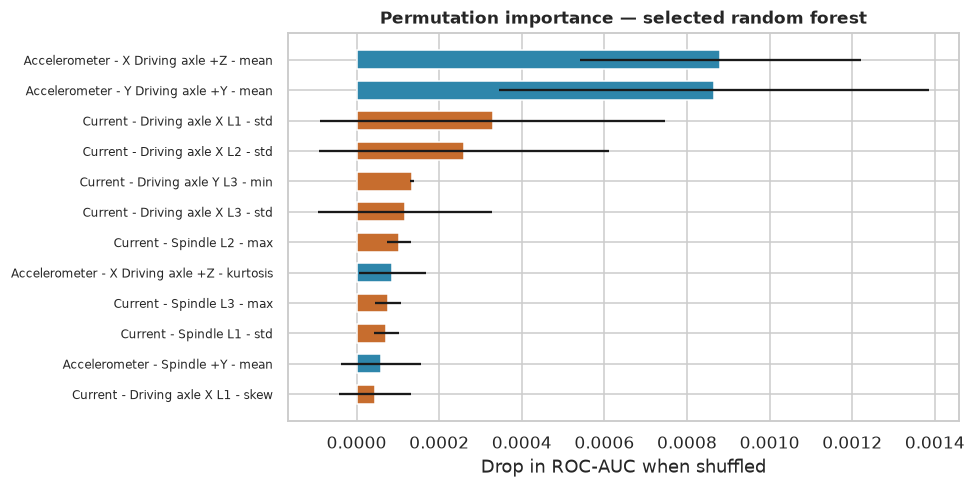

In [13]:
final_pipe = base_pipeline("RandomForest", params={"clf__min_samples_leaf": 3, "clf__max_depth": 6})
final_pipe.fit(X, y)

perm = permutation_importance(
    final_pipe, X, y, scoring="roc_auc", n_repeats=5,
    random_state=RANDOM_STATE, n_jobs=1,
)
importance = (
    pd.DataFrame({"feature": SENSOR_COLUMNS,
                  "importance_mean": perm.importances_mean,
                  "importance_std": perm.importances_std})
    .sort_values("importance_mean", ascending=False)
    .reset_index(drop=True)
)
display(importance.head(12).round(4))

top = importance.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(range(len(top)), top["importance_mean"], xerr=top["importance_std"],
        color=["#2E86AB" if f.startswith("Accelerometer") else "#C76D2E" for f in top["feature"]],
        height=0.62)
ax.set_yticks(range(len(top)), top["feature"], fontsize=8)
ax.set_xlabel("Drop in ROC-AUC when shuffled")
ax.set_title("Permutation importance — selected random forest")
fig.tight_layout()
plt.show()

Drive-axis mean acceleration dominates, followed by drive and spindle current variability. That is
consistent with the physics of a deeper radial engagement: the mean vibration level shifts and the
current becomes more variable as the load rises. The model is not keying on an identifier, a wear
counter or a process setting — those columns are not in `X`.

## 8. Demonstration on previously unseen cases

The required demonstration uses two **experiments never used in training**: P002 (RDOC = 8 mm,
dangerous) and P108 (RDOC = 4.5 mm, optimal). A fresh forest with the selected hyperparameters is
fitted on the remaining 22 experiments and then applied to both. This is a stricter test than
scoring training cycles, because the model never sees either experiment or its layer structure.

In [14]:
holdout_mask = clean["is_demo_holdout"].astype(int).to_numpy() == 1
print(f"Training cycles: {(~holdout_mask).sum()};  held-out cycles: {holdout_mask.sum()}")

demo_pipe = base_pipeline("RandomForest", params={"clf__min_samples_leaf": 3, "clf__max_depth": 6})
demo_pipe.fit(X.loc[~holdout_mask], y[~holdout_mask])
demo_prob = demo_pipe.predict_proba(X.loc[holdout_mask])[:, 1]

demo = clean.loc[holdout_mask, ["FileName", "ExperimentID", "ToolIndex", "MillingToolType",
                                "CycleToFailure", "RDOC_class", "class_label"]].copy()
demo["prob_dangerous"] = demo_prob
demo["pred_dangerous"] = (demo_prob >= threshold).astype(int)
demo["correct"] = (demo["pred_dangerous"] == demo["RDOC_class"]).astype(int)

summary = (
    demo.groupby(["ExperimentID", "class_label"], as_index=False)
    .agg(cycles=("FileName", "size"), prob_mean=("prob_dangerous", "mean"),
         prob_min=("prob_dangerous", "min"), prob_max=("prob_dangerous", "max"),
         frac_flagged=("pred_dangerous", "mean"))
)
display(summary.round(3))

representatives = (
    demo.sort_values("CycleToFailure", ascending=False)
    .groupby("ExperimentID").head(1)
    .sort_values("ExperimentID")
)
display(representatives[["FileName", "ExperimentID", "class_label", "CycleToFailure",
                         "prob_dangerous", "pred_dangerous", "correct"]].round(3))

Training cycles: 841;  held-out cycles: 127


,ExperimentID,class_label,cycles,prob_mean,prob_min,prob_max,frac_flagged
0,P002,Non-optimal (RDOC 8 mm),46,0.746,0.439,0.953,0.978
1,P108,Optimal (RDOC 4.5 mm),81,0.006,0.000,0.046,0.000


,FileName,ExperimentID,class_label,CycleToFailure,prob_dangerous,pred_dangerous,correct
0,P002_F01_C1,P002,Non-optimal (RDOC 8 mm),49,0.439,0,0
745,P108_F01_C1,P108,Optimal (RDOC 4.5 mm),84,0.037,0,1


P108 (optimal) is correctly cleared on all 81 cycles, with a mean probability near zero. P002
(dangerous) is flagged on 45 of 46 cycles; the one miss is the first cycle of the experiment, where
the tool is fresh and the vibration/current level has not yet drifted upward. That single miss is a
useful engineering finding: a safety monitor should not rely on a single cycle at the start of a
tool's life, and a short rolling window would be more robust.

Below, the fitted forest scores one individual cycle through the same interface a deployment would
use: a single row of 120 sensor statistics, no metadata.

In [15]:
single = clean.loc[clean["FileName"] == "P002_F12_C4"].iloc[0]
x_new = clean.loc[[single.name], SENSOR_COLUMNS]
p_new = float(final_pipe.predict_proba(x_new)[0, 1])

print(f"Cycle         : {single['FileName']}  (experiment {single['ExperimentID']}, tool {int(single['ToolIndex'])})")
print(f"Actual class  : {single['class_label']}")
print(f"P(dangerous)  : {p_new:.3f}")
print(f"Decision      : {'FLAG — dangerous condition' if p_new >= threshold else 'clear — optimal condition'}")
print(f"Threshold     : {threshold:.3f}")

Cycle         : P002_F12_C4  (experiment P002, tool 2)
Actual class  : Non-optimal (RDOC 8 mm)
P(dangerous)  : 0.967
Decision      : FLAG — dangerous condition
Threshold     : 0.444


## 9. Engineering interpretation, limitations and recommendations

**Interpretation.** The classifier is effectively a data-driven cutting-force monitor. A larger radial
engagement raises the mean drive-axis acceleration and the variability of the drive/spindle current;
the forest combines several correlated channels and flags the condition with 96 % recall at the tuned
operating point. This is plausible from metal-cutting mechanics and does not depend on tool identity
for its signal (grouped validation, leave-one-tool-out and held-out experiments all agree).

**Limitations.**

- **Confounded experimental design.** RDOC is constant within a tool and an experiment, so RDOC,
  tool geometry, material batch and wear stage are entangled. Grouped validation limits the optimism
  but cannot fully separate these causes with this dataset.
- **Wear confound.** Dangerous tools fail sooner and sensor features drift with remaining life, so
  some of the separation may be wear rather than RDOC. The dashboard's probability-vs-life view
  makes this visible.
- **Small tool count.** 14 tools, 5 of them dangerous. Leave-one-tool-out is the relevant stress test,
  and tool 7 is a persistent false-positive source.
- **Raw signals unavailable.** Models use the authors' 120 pre-computed statistics; the 25 GB raw
  waveforms were not available, so window length and filtering cannot be re-optimised.
- **No calibrated units.** Accelerometer and current values are raw ADC counts, so thresholds are
  dataset-specific and would need recalibration on another machine.
- **Threshold is a policy choice.** 0.44 favours recall. A plant with cheap inspection and expensive
  scrap may prefer a higher threshold; the dashboard exposes the trade-off.

**Recommendations.**

1. Deploy as a **decision-support alarm**, not an automatic stop: require two consecutive flagged
   cycles or a rolling mean before retracting the tool.
2. Log the probability and the top contributing features for every cycle so a process engineer can
   audit alarms.
3. Re-validate on a campaign where the same tool is run at both RDOC levels; that design would break
   the confounding and give a genuinely causal estimate.
4. Calibrate sensor channels to g and A before transferring the model to another machine.
5. Re-tune the threshold per shop-floor cost ratio (missed dangerous cut vs false alarm).

## 10. Reproduce the saved artifacts

```bash
# from the project root
.venv/bin/python -m src.data                 # cleaning, audit, folds, long sensor table
.venv/bin/python scripts/02_eda.py           # figures 01-06 and EDA_INSIGHTS.md
.venv/bin/python scripts/03_modeling.py      # model comparison, figures 07-10
.venv/bin/python scripts/05_select_rf.py     # final model, threshold, unseen cases, figure 11
.venv/bin/python scripts/06_tableau_export.py
streamlit run dashboard/app.py               # interactive dashboard
```

Saved outputs: `data/processed/` (cleaned data, audit, folds, data dictionary), `models/` (final
model, metrics, predictions, unseen-case evidence), `figures/` (report and dashboard figures),
`reports/` (EDA insights and technical report), `dashboard/tableau/` (Tableau extracts and guide).